# Drug Target Agent — Full 4-Stage Pipeline Test

Single L-R pair (TGFB1 → TGFBR2)에 대해 Drug Target Agent의 12개 @tool을 순서대로 테스트합니다.

| Stage | Tools | Description |
|-------|-------|-------------|
| 1 | #1-#5 | Biological Context (Census, KEGG, Reactome, STRING) |
| 2 | #6-#8 | Target Validation (OpenTargets, GWAS) |
| 3 | #9-#10 | Deep Dive (DrugBank, PubMed) |
| 4 | #11 | Structural Druggability (AlphaFold) |

## Setup

In [1]:
import json
import time
import os
import sys

# 프로젝트 루트를 path에 추가
PROJECT_ROOT = os.path.abspath(os.path.join(os.getcwd(), ".."))
if PROJECT_ROOT not in sys.path:
    sys.path.insert(0, PROJECT_ROOT)

print(f"Project root: {PROJECT_ROOT}")

Project root: /Users/jungj2/Dropbox/Metadata/aiagent/DeepMAST


In [2]:
from src.agents.drug_target.tools import (
    # Stage 1: Biological Context
    query_cellxgene_lr_context,       # #1
    query_kegg_pathways,              # #2
    query_reactome_pathways,          # #3
    query_string_ppi_pair,            # #4
    run_compare_census_lr_pair,       # #5
    # Stage 2: Target Validation
    query_opentargets_target,         # #6
    query_opentargets_known_drugs,    # #7
    query_gwas_gene_trait,            # #8
    # Stage 3: Deep Dive
    query_drugbank_target_profile,    # #9
    query_pubmed_clinical_limitations,# #10
    # Stage 4: Structural Druggability
    query_alphafold_plddt,            # #11
)

print("All 11 domain tools imported OK")

All 11 domain tools imported OK


In [3]:
# 테스트 파라미터
DISEASE = "breast cancer"
LIGAND = "TGFB1"
RECEPTOR = "TGFBR2"
TARGET_CELL_TYPE = "macrophage"
ORGANISM = "homo_sapiens"
DATA_DIR = "check_drugtarget"

# UniProt IDs for AlphaFold
UNIPROT_LIGAND = "P01137"   # TGFB1
UNIPROT_RECEPTOR = "P37173" # TGFBR2

os.makedirs(DATA_DIR, exist_ok=True)
os.makedirs(os.path.join(DATA_DIR, "evidence"), exist_ok=True)

print(f"Disease: {DISEASE}")
print(f"L-R pair: {LIGAND} -> {RECEPTOR}")
print(f"Target cell type: {TARGET_CELL_TYPE}")
print(f"Data dir: {DATA_DIR}")

Disease: breast cancer
L-R pair: TGFB1 -> TGFBR2
Target cell type: macrophage
Data dir: check_drugtarget


In [4]:
# Helper: run tool and collect timing
timings = {}
results = {}

def run_tool(name, tool_fn, params):
    """Run a tool, parse JSON result, store timing."""
    print(f"\n{'='*60}")
    print(f"Running: {name}")
    print(f"Params: {params}")
    print(f"{'='*60}")
    t0 = time.time()
    try:
        raw = tool_fn.invoke(params)
        elapsed = time.time() - t0
        result = json.loads(raw)
        timings[name] = elapsed
        results[name] = result
        status = "OK" if result.get("executed", False) else "FAIL"
        errors = result.get("errors", [])
        print(f"Status: {status} | Time: {elapsed:.1f}s")
        if errors:
            print(f"Errors: {errors}")
        return result
    except Exception as e:
        elapsed = time.time() - t0
        timings[name] = elapsed
        results[name] = {"executed": False, "errors": [str(e)]}
        print(f"EXCEPTION: {e} | Time: {elapsed:.1f}s")
        return results[name]

print("Helper ready")

Helper ready


---
## Stage 1: Biological Context (Tools #1-#5)

In [5]:
# #1 CELLxGENE Census — L-R pair 세포타입별 발현
r1 = run_tool("#1 cellxgene_lr_context", query_cellxgene_lr_context, {
    "ligand": LIGAND,
    "receptor": RECEPTOR,
    "disease": DISEASE,
    "organism": ORGANISM,
})
print(f"\nCell count: {r1.get('cell_count', 0):,}")
print(f"Available genes: {r1.get('available_genes', [])}")
for ct in r1.get('top_cell_types', []):
    print(f"  {ct['cell_type']}: {ct['count']:,}")


Running: #1 cellxgene_lr_context
Params: {'ligand': 'TGFB1', 'receptor': 'TGFBR2', 'disease': 'breast cancer', 'organism': 'homo_sapiens'}


The "stable" release is currently 2025-11-08. Specify 'census_version="2025-11-08"' in future calls to open_soma() to ensure data consistency.


Status: OK | Time: 8.3s

Cell count: 1,101,430
Available genes: ['TGFB1', 'TGFBR2']
  malignant cell: 576,171
  macrophage: 80,485
  T cell: 75,981
  hepatocyte: 67,435
  fibroblast: 62,959


In [6]:
# #2 KEGG Pathways — Ligand
r2a = run_tool("#2a kegg_ligand", query_kegg_pathways, {
    "gene_symbol": LIGAND,
})
for pw in r2a.get('pathways', []):
    print(f"  {pw['pathway_id']}: {pw['name']}")


Running: #2a kegg_ligand
Params: {'gene_symbol': 'TGFB1'}
Status: OK | Time: 2.2s


In [7]:
# #2 KEGG Pathways — Receptor
r2b = run_tool("#2b kegg_receptor", query_kegg_pathways, {
    "gene_symbol": RECEPTOR,
})
for pw in r2b.get('pathways', []):
    print(f"  {pw['pathway_id']}: {pw['name']}")


Running: #2b kegg_receptor
Params: {'gene_symbol': 'TGFBR2'}
Status: OK | Time: 6.7s
  hsa04010: MAPK signaling pathway - Homo sapiens (human)
  hsa04060: Cytokine-cytokine receptor interaction - Homo sapiens (human)
  hsa04068: FoxO signaling pathway - Homo sapiens (human)
  hsa04144: Endocytosis - Homo sapiens (human)
  hsa04218: Cellular senescence - Homo sapiens (human)


In [8]:
# #3 Reactome Pathways — Ligand
r3a = run_tool("#3a reactome_ligand", query_reactome_pathways, {
    "gene_symbol": LIGAND,
})
for pw in r3a.get('pathways', []):
    print(f"  {pw['reactome_id']}: {pw['name']}")


Running: #3a reactome_ligand
Params: {'gene_symbol': 'TGFB1'}
Status: OK | Time: 0.3s
  R-HSA-2173789: TGF-beta receptor signaling activates SMADs
  R-HSA-3642279: TGFBR2 MSI Frameshift Mutants in Cancer
  R-HSA-3645790: TGFBR2 Kinase Domain Mutants in Cancer
  R-HSA-8941855: RUNX3 regulates CDKN1A transcription
  R-HSA-9762293: Regulation of CDH11 gene transcription


In [9]:
# #3 Reactome Pathways — Receptor
r3b = run_tool("#3b reactome_receptor", query_reactome_pathways, {
    "gene_symbol": RECEPTOR,
})
for pw in r3b.get('pathways', []):
    print(f"  {pw['reactome_id']}: {pw['name']}")


Running: #3b reactome_receptor
Params: {'gene_symbol': 'TGFBR2'}
Status: OK | Time: 0.3s
  R-HSA-3642278: Loss of Function of TGFBR2 in Cancer
  R-HSA-3642279: TGFBR2 MSI Frameshift Mutants in Cancer
  R-HSA-3645790: TGFBR2 Kinase Domain Mutants in Cancer
  R-HSA-2173789: TGF-beta receptor signaling activates SMADs
  R-HSA-3304351: Signaling by TGF-beta Receptor Complex in Cancer


In [10]:
# #4 STRING PPI
r4 = run_tool("#4 string_ppi", query_string_ppi_pair, {
    "gene_a": LIGAND,
    "gene_b": RECEPTOR,
})
print(f"\nInteraction found: {r4.get('interaction_found')}")
print(f"Max combined score: {r4.get('max_combined_score')}")
if r4.get('ppi_enrichment'):
    print(f"PPI enrichment: {r4['ppi_enrichment']}")


Running: #4 string_ppi
Params: {'gene_a': 'TGFB1', 'gene_b': 'TGFBR2'}
Status: OK | Time: 0.5s

Interaction found: True
Max combined score: 0.999
PPI enrichment: {'number_of_nodes': 2, 'number_of_edges': 1, 'average_node_degree': 1.0, 'local_clustering_coefficient': 1.0, 'expected_number_of_edges': 0, 'p_value': 0.1352}


In [11]:
# #5 Census Compare (z-test) — 시간이 오래 걸림 (~90s)
r5 = run_tool("#5 census_compare", run_compare_census_lr_pair, {
    "data_dir": DATA_DIR,
    "disease": DISEASE,
    "gene_a": LIGAND,
    "gene_b": RECEPTOR,
    "target_cell_type": TARGET_CELL_TYPE,
    "organism": ORGANISM,
    "min_cells": 50,
    "top_n": 20,
    "timeout_sec": 180,
})
if r5.get('target_vs_rest'):
    tvr = r5['target_vs_rest']
    print(f"\nTarget vs Rest ({TARGET_CELL_TYPE}):")
    for gene_key in ['gene_a', 'gene_b', 'coexpression']:
        if gene_key in tvr:
            d = tvr[gene_key]
            print(f"  {gene_key}: target={d.get('target_pct',0):.1%} rest={d.get('rest_pct',0):.1%} RR={d.get('risk_ratio',0):.2f} p={d.get('p_value','?')}")


Running: #5 census_compare
Params: {'data_dir': 'check_drugtarget', 'disease': 'breast cancer', 'gene_a': 'TGFB1', 'gene_b': 'TGFBR2', 'target_cell_type': 'macrophage', 'organism': 'homo_sapiens', 'min_cells': 50, 'top_n': 20, 'timeout_sec': 180}
Status: OK | Time: 103.3s

Target vs Rest (macrophage):
  gene_a: target=23.5% rest=14.1% RR=1.66 p=1e-323
  gene_b: target=26.8% rest=15.1% RR=1.78 p=1e-323
  coexpression: target=10.0% rest=4.1% RR=2.43 p=1e-323


---
## Stage 2: Target Validation & Scoring (Tools #6-#8)

In [12]:
# #6 OpenTargets Target — Ligand
r6a = run_tool("#6a opentargets_ligand", query_opentargets_target, {
    "gene_symbol": LIGAND,
    "disease": DISEASE,
})
print(f"\nEnsembl ID: {r6a.get('ensembl_id')}")
print(f"EFO ID: {r6a.get('efo_id')}")
ti = r6a.get('target_info', {})
if ti:
    print(f"Tractability: {ti.get('tractability', 'N/A')}")
    print(f"Safety: {ti.get('safety', 'N/A')}")
print(f"Disease evidence count: {len(r6a.get('disease_evidence', []))}")
print(f"Associations count: {len(r6a.get('associations', []))}")


Running: #6a opentargets_ligand
Params: {'gene_symbol': 'TGFB1', 'disease': 'breast cancer'}
Status: OK | Time: 1.7s

Ensembl ID: ENSG00000105329
EFO ID: MONDO_0007254
Tractability: [{'label': 'Approved Drug', 'modality': 'SM', 'value': False}, {'label': 'Advanced Clinical', 'modality': 'SM', 'value': False}, {'label': 'Phase 1 Clinical', 'modality': 'SM', 'value': False}, {'label': 'Structure with Ligand', 'modality': 'SM', 'value': True}, {'label': 'High-Quality Ligand', 'modality': 'SM', 'value': False}, {'label': 'High-Quality Pocket', 'modality': 'SM', 'value': False}, {'label': 'Med-Quality Pocket', 'modality': 'SM', 'value': True}, {'label': 'Druggable Family', 'modality': 'SM', 'value': True}, {'label': 'Approved Drug', 'modality': 'AB', 'value': False}, {'label': 'Advanced Clinical', 'modality': 'AB', 'value': True}, {'label': 'Phase 1 Clinical', 'modality': 'AB', 'value': False}, {'label': 'UniProt loc high conf', 'modality': 'AB', 'value': True}, {'label': 'GO CC high conf'

In [13]:
# #6 OpenTargets Target — Receptor
r6b = run_tool("#6b opentargets_receptor", query_opentargets_target, {
    "gene_symbol": RECEPTOR,
    "disease": DISEASE,
})
print(f"\nEnsembl ID: {r6b.get('ensembl_id')}")
print(f"EFO ID: {r6b.get('efo_id')}")
ti = r6b.get('target_info', {})
if ti:
    print(f"Tractability: {ti.get('tractability', 'N/A')}")
    print(f"Safety: {ti.get('safety', 'N/A')}")
print(f"Disease evidence count: {len(r6b.get('disease_evidence', []))}")
print(f"Associations count: {len(r6b.get('associations', []))}")


Running: #6b opentargets_receptor
Params: {'gene_symbol': 'TGFBR2', 'disease': 'breast cancer'}
Status: OK | Time: 1.0s

Ensembl ID: ENSG00000163513
EFO ID: MONDO_0007254
Tractability: [{'label': 'Approved Drug', 'modality': 'SM', 'value': False}, {'label': 'Advanced Clinical', 'modality': 'SM', 'value': False}, {'label': 'Phase 1 Clinical', 'modality': 'SM', 'value': False}, {'label': 'Structure with Ligand', 'modality': 'SM', 'value': True}, {'label': 'High-Quality Ligand', 'modality': 'SM', 'value': True}, {'label': 'High-Quality Pocket', 'modality': 'SM', 'value': False}, {'label': 'Med-Quality Pocket', 'modality': 'SM', 'value': False}, {'label': 'Druggable Family', 'modality': 'SM', 'value': True}, {'label': 'Approved Drug', 'modality': 'AB', 'value': False}, {'label': 'Advanced Clinical', 'modality': 'AB', 'value': False}, {'label': 'Phase 1 Clinical', 'modality': 'AB', 'value': False}, {'label': 'UniProt loc high conf', 'modality': 'AB', 'value': True}, {'label': 'GO CC high c

In [14]:
# #7 OpenTargets Known Drugs
r7 = run_tool("#7 opentargets_drugs", query_opentargets_known_drugs, {
    "disease": DISEASE,
})
print(f"\nEFO ID: {r7.get('efo_id')}")
drugs = r7.get('drugs', {})
if isinstance(drugs, dict):
    print(f"Drug count: {drugs.get('count', len(drugs))}")
elif isinstance(drugs, list):
    print(f"Drug count: {len(drugs)}")
    for d in drugs[:5]:
        print(f"  {d}")


Running: #7 opentargets_drugs
Params: {'disease': 'breast cancer'}
Status: OK | Time: 0.4s

EFO ID: MONDO_0007254
Drug count: 3


In [15]:
# #8 GWAS — Ligand
r8a = run_tool("#8a gwas_ligand", query_gwas_gene_trait, {
    "gene_symbol": LIGAND,
    "disease": DISEASE,
})
print(f"\nEFO traits: {len(r8a.get('efo_traits', []))}")
print(f"Trait associations: {len(r8a.get('trait_associations', []))}")
print(f"Gene associations: {len(r8a.get('gene_associations', []))}")


Running: #8a gwas_ligand
Params: {'gene_symbol': 'TGFB1', 'disease': 'breast cancer'}
Status: OK | Time: 35.5s

EFO traits: 1
Trait associations: 50
Gene associations: 20


In [16]:
# #8 GWAS — Receptor
r8b = run_tool("#8b gwas_receptor", query_gwas_gene_trait, {
    "gene_symbol": RECEPTOR,
    "disease": DISEASE,
})
print(f"\nEFO traits: {len(r8b.get('efo_traits', []))}")
print(f"Trait associations: {len(r8b.get('trait_associations', []))}")
print(f"Gene associations: {len(r8b.get('gene_associations', []))}")


Running: #8b gwas_receptor
Params: {'gene_symbol': 'TGFBR2', 'disease': 'breast cancer'}
Status: OK | Time: 35.7s

EFO traits: 1
Trait associations: 50
Gene associations: 20


---
## Stage 2b: VEP (조건부) + RUBRIC 점수화

In [ ]:
# --- VEP 조건 판단 ---
from src.agents.drug_target.tools.stage_logic import (
    should_run_vep, infer_oncology_flag, classify_vep_consequence,
    classify_target, compute_priority, compute_validated_track, compute_exploratory_track,
    validate_rubric_assessment,
)

oncology_flag = infer_oncology_flag(DISEASE)
print(f"Disease: {DISEASE}")
print(f"Oncology flag: {oncology_flag}")

# GWAS gene_associations에서 rs ID 유무 확인
has_gwas = False
for gwas_result in [r8a, r8b]:
    for assoc in gwas_result.get("gene_associations", []):
        if (assoc.get("rsId") or assoc.get("snp") or "").startswith("rs"):
            has_gwas = True
            break

print(f"Has GWAS variants: {has_gwas}")
print(f"should_run_vep: {should_run_vep(oncology_flag=oncology_flag, has_gwas_variants=has_gwas)}")

In [ ]:
# --- #8c VEP (조건부 실행) ---
from src.agents.drug_target.tools import query_ensembl_vep_consequence

run_vep = should_run_vep(oncology_flag=oncology_flag, has_gwas_variants=has_gwas)

if run_vep:
    # GWAS gene_associations에서 rs ID 수집
    variant_ids = set()
    for gwas_result in [r8a, r8b]:
        for assoc in gwas_result.get("gene_associations", []):
            rs = assoc.get("rsId") or assoc.get("snp") or ""
            if rs.startswith("rs"):
                variant_ids.add(rs)

    variant_ids = sorted(variant_ids)[:10]  # 최대 10개
    print(f"VEP에 전달할 variant IDs ({len(variant_ids)}개): {variant_ids}")

    if variant_ids:
        r_vep = run_tool("#8c vep", query_ensembl_vep_consequence, {
            "variant_ids": ",".join(variant_ids),
        })
        print(f"\nVariant consequences:")
        for v in r_vep.get("variants", []):
            consequence = v.get("most_severe_consequence", "?")
            impact = classify_vep_consequence(consequence)
            print(f"  {v.get('id')}: {consequence} [{impact}]")
    else:
        print("GWAS에서 rs ID를 찾지 못함 → VEP 건너뜀")
        r_vep = {"executed": False, "errors": ["No variant IDs from GWAS"]}
else:
    print(f"VEP 조건 미충족 (oncology={oncology_flag}, has_gwas={has_gwas}) → 건너뜀")
    r_vep = {"executed": False, "errors": ["VEP gate not met"]}

In [19]:
# --- RUBRIC 점수화: 수집된 증거로 assessment 구성 ---
# Stage 2에서 수집한 데이터를 기반으로 각 유전자의 RUBRIC assessment를 구성

def build_assessment_from_evidence(gene, ot_result, gwas_result, census_result, disease):
    """수집된 evidence를 기반으로 RUBRIC assessment dict 구성."""
    ti = ot_result.get("target_info", {})
    tractability = ti.get("tractability", [])
    associations = ot_result.get("associations", [])
    disease_evidence = ot_result.get("disease_evidence", [])
    gene_assocs = gwas_result.get("gene_associations", [])

    # --- Validated Track ---
    # existing_drug_evidence: approved drug in tractability?
    has_approved_sm = any(t.get("label") == "Approved Drug" and t.get("value") and t.get("modality") == "SM" for t in tractability)
    has_approved_ab = any(t.get("label") == "Approved Drug" and t.get("value") and t.get("modality") == "AB" for t in tractability)
    has_advanced = any(t.get("label") == "Advanced Clinical" and t.get("value") for t in tractability)
    ede = 3 if (has_approved_sm or has_approved_ab) else (2 if has_advanced else (1 if disease_evidence else 0))

    # clinical_trial_activity: phase from tractability
    has_phase1 = any(t.get("label") == "Phase 1 Clinical" and t.get("value") for t in tractability)
    cta = 2 if has_advanced else (1 if has_phase1 else (1 if len(disease_evidence) > 10 else 0))

    # mechanism_relevance: from disease evidence count + associations
    mech = 3 if len(disease_evidence) >= 50 else (2 if len(disease_evidence) >= 10 else (1 if disease_evidence else 0))

    # safety_profile: 0 (no known issues) to -2 (serious)
    safety = 0  # default: no known safety issues

    # --- Exploratory Track ---
    # gwas_genetic_support
    sig_gwas = [a for a in gene_assocs if float(a.get("pValue", a.get("p_value", 1))) < 5e-8] if gene_assocs else []
    gwas_score = 3 if len(sig_gwas) >= 3 else (2 if len(sig_gwas) >= 1 else (1 if gene_assocs else 0))

    # tractability score
    sm_tractable = any(t.get("label") in ("Structure with Ligand", "High-Quality Ligand", "Druggable Family") and t.get("value") for t in tractability)
    ab_tractable = any(t.get("label") in ("UniProt loc high conf", "GO CC high conf") and t.get("value") for t in tractability)
    tract_score = 3 if (sm_tractable and ab_tractable) else (2 if sm_tractable else (1 if ab_tractable else 0))

    # biological_plausibility: associations count
    bio = 3 if len(associations) >= 50 else (2 if len(associations) >= 10 else (1 if associations else 0))

    # novelty_opportunity
    novelty = 1 if not (has_approved_sm or has_approved_ab) else 0

    return {
        "gene": gene,
        "validated_track": {
            "existing_drug_evidence": {"score": ede, "rationale": f"approved_SM={has_approved_sm}, approved_AB={has_approved_ab}, advanced={has_advanced}"},
            "clinical_trial_activity": {"score": cta, "rationale": f"advanced={has_advanced}, phase1={has_phase1}, evidence_count={len(disease_evidence)}"},
            "mechanism_relevance": {"score": mech, "rationale": f"disease_evidence={len(disease_evidence)}"},
            "safety_profile": {"score": safety, "rationale": "No known safety signals"},
        },
        "exploratory_track": {
            "gwas_genetic_support": {"score": gwas_score, "rationale": f"genome-wide significant hits: {len(sig_gwas)}"},
            "tractability": {"score": tract_score, "rationale": f"SM={sm_tractable}, AB={ab_tractable}"},
            "biological_plausibility": {"score": bio, "rationale": f"associations={len(associations)}"},
            "novelty_opportunity": {"score": novelty, "rationale": f"no approved drug = {not (has_approved_sm or has_approved_ab)}"},
        },
    }

# Census validation 결과 추출
census_tvr = r5.get("target_vs_rest", {})

# TGFB1 assessment
assessment_ligand = build_assessment_from_evidence(LIGAND, r6a, r8a, census_tvr, DISEASE)

# TGFBR2 assessment
assessment_receptor = build_assessment_from_evidence(RECEPTOR, r6b, r8b, census_tvr, DISEASE)

print("RUBRIC assessments built from collected evidence")
print(f"  {LIGAND}: validated_track scores = { {k: v['score'] for k, v in assessment_ligand['validated_track'].items()} }")
print(f"  {RECEPTOR}: validated_track scores = { {k: v['score'] for k, v in assessment_receptor['validated_track'].items()} }")

RUBRIC assessments built from collected evidence
  TGFB1: validated_track scores = {'existing_drug_evidence': 2, 'clinical_trial_activity': 2, 'mechanism_relevance': 3, 'safety_profile': 0}
  TGFBR2: validated_track scores = {'existing_drug_evidence': 1, 'clinical_trial_activity': 1, 'mechanism_relevance': 3, 'safety_profile': 0}


In [20]:
# --- RUBRIC 검증 + 분류 + 우선순위 ---
print("=" * 70)
print("RUBRIC Scoring Results")
print("=" * 70)

for label, assessment in [(LIGAND, assessment_ligand), (RECEPTOR, assessment_receptor)]:
    print(f"\n{'─' * 60}")
    print(f"  Gene: {label}")
    print(f"{'─' * 60}")

    # 1) Schema validation
    errors = validate_rubric_assessment(assessment)
    if errors:
        print(f"  ⚠ Validation errors: {errors}")
    else:
        print(f"  ✓ Schema validation passed")

    # 2) Validated track
    vt = compute_validated_track(assessment)
    print(f"\n  Validated Track (total={vt['total']}, pass={vt['pass']}):")
    for k, v in vt["scores"].items():
        rationale = assessment["validated_track"][k].get("rationale", "")
        print(f"    {k}: {v}  ({rationale})")

    # 3) Exploratory track
    et = compute_exploratory_track(assessment)
    print(f"\n  Exploratory Track (total={et['total']}, pass={et['pass']}):")
    for k, v in et["scores"].items():
        rationale = assessment["exploratory_track"][k].get("rationale", "")
        print(f"    {k}: {v}  ({rationale})")

    # 4) Classification + Priority
    classification = classify_target(assessment)
    priority = compute_priority(assessment)
    print(f"\n  → Classification: {classification}")
    print(f"  → Priority: {priority}")

# 결과 저장
rubric_results = {}
for label, assessment in [(LIGAND, assessment_ligand), (RECEPTOR, assessment_receptor)]:
    rubric_results[label] = {
        "assessment": assessment,
        "validated_track": compute_validated_track(assessment),
        "exploratory_track": compute_exploratory_track(assessment),
        "classification": classify_target(assessment),
        "priority": compute_priority(assessment),
    }

# evidence 디렉토리에 저장
rubric_path = os.path.join(DATA_DIR, "evidence", "rubric_scores.json")
with open(rubric_path, "w") as f:
    json.dump(rubric_results, f, indent=2, default=str)
print(f"\n✓ RUBRIC scores saved: {rubric_path}")

RUBRIC Scoring Results

────────────────────────────────────────────────────────────
  Gene: TGFB1
────────────────────────────────────────────────────────────
  ✓ Schema validation passed

  Validated Track (total=7, pass=True):
    existing_drug_evidence: 2  (approved_SM=False, approved_AB=False, advanced=True)
    clinical_trial_activity: 2  (advanced=True, phase1=False, evidence_count=100)
    mechanism_relevance: 3  (disease_evidence=100)
    safety_profile: 0  (No known safety signals)

  Exploratory Track (total=8, pass=True):
    gwas_genetic_support: 1  (genome-wide significant hits: 0)
    tractability: 3  (SM=True, AB=True)
    biological_plausibility: 3  (associations=100)
    novelty_opportunity: 1  (no approved drug = True)

  → Classification: validated_target
  → Priority: high

────────────────────────────────────────────────────────────
  Gene: TGFBR2
────────────────────────────────────────────────────────────
  ✓ Schema validation passed

  Validated Track (total=5,

---
## Stage 3: Deep Dive (Tools #9-#10)

In [21]:
# #9 DrugBank — Ligand
r9a = run_tool("#9a drugbank_ligand", query_drugbank_target_profile, {
    "gene_symbol": LIGAND,
})
print(f"\nSource: {r9a.get('source')}")
print(f"Matched drugs: {len(r9a.get('matched_drugs', []))}")
for d in r9a.get('matched_drugs', [])[:5]:
    print(f"  {d.get('drug_name', '?')} ({d.get('drugbank_id') or d.get('chembl_id', '?')})")


Running: #9a drugbank_ligand
Params: {'gene_symbol': 'TGFB1'}
Status: FAIL | Time: 0.0s
Errors: ["DrugBank unavailable: No module named 'drugbank_downloader'", "ChEMBL fallback also failed: No module named 'chembl_webresource_client'"]

Source: None
Matched drugs: 0


In [22]:
# #9 DrugBank — Receptor
r9b = run_tool("#9b drugbank_receptor", query_drugbank_target_profile, {
    "gene_symbol": RECEPTOR,
})
print(f"\nSource: {r9b.get('source')}")
print(f"Matched drugs: {len(r9b.get('matched_drugs', []))}")
for d in r9b.get('matched_drugs', [])[:5]:
    print(f"  {d.get('drug_name', '?')} ({d.get('drugbank_id') or d.get('chembl_id', '?')})")


Running: #9b drugbank_receptor
Params: {'gene_symbol': 'TGFBR2'}
Status: FAIL | Time: 0.0s
Errors: ["DrugBank unavailable: No module named 'drugbank_downloader'", "ChEMBL fallback also failed: No module named 'chembl_webresource_client'"]

Source: None
Matched drugs: 0


In [23]:
# #10 PubMed Clinical Limitations — both genes
r10a = run_tool("#10a pubmed_ligand", query_pubmed_clinical_limitations, {
    "target_name": LIGAND,
})
print(f"\nPapers found: {len(r10a.get('papers', []))}")
for p in r10a.get('papers', []):
    print(f"  [{p.get('year', '?')}] PMID:{p.get('pmid', '?')} - {p.get('title', '?')[:80]}")


Running: #10a pubmed_ligand
Params: {'target_name': 'TGFB1'}
Status: OK | Time: 0.3s

Papers found: 0


In [24]:
r10b = run_tool("#10b pubmed_receptor", query_pubmed_clinical_limitations, {
    "target_name": RECEPTOR,
})
print(f"\nPapers found: {len(r10b.get('papers', []))}")
for p in r10b.get('papers', []):
    print(f"  [{p.get('year', '?')}] PMID:{p.get('pmid', '?')} - {p.get('title', '?')[:80]}")


Running: #10b pubmed_receptor
Params: {'target_name': 'TGFBR2'}
Status: OK | Time: 0.3s

Papers found: 0


---
## Stage 4: Structural Druggability (Tool #11)

In [25]:
# #11 AlphaFold pLDDT — Ligand
r11a = run_tool("#11a alphafold_ligand", query_alphafold_plddt, {
    "uniprot_id": UNIPROT_LIGAND,
})
print(f"\nEntry ID: {r11a.get('entry_id')}")
print(f"Mean pLDDT: {r11a.get('mean_plddt')}")


Running: #11a alphafold_ligand
Params: {'uniprot_id': 'P01137'}
Status: OK | Time: 0.3s

Entry ID: AF-P01137-F1
Mean pLDDT: 79.589


In [26]:
# #11 AlphaFold pLDDT — Receptor
r11b = run_tool("#11b alphafold_receptor", query_alphafold_plddt, {
    "uniprot_id": UNIPROT_RECEPTOR,
})
print(f"\nEntry ID: {r11b.get('entry_id')}")
print(f"Mean pLDDT: {r11b.get('mean_plddt')}")


Running: #11b alphafold_receptor
Params: {'uniprot_id': 'P37173'}
Status: OK | Time: 0.4s

Entry ID: AF-P37173-F1
Mean pLDDT: 80.981


---
## Summary

In [27]:
# Timing summary
print(f"{'Tool':<30} {'Time (s)':>10} {'Status':>8}")
print("-" * 50)
total = 0
for name, t in timings.items():
    status = "OK" if results.get(name, {}).get('executed', False) else "FAIL"
    print(f"{name:<30} {t:>10.1f} {status:>8}")
    total += t
print("-" * 50)
print(f"{'TOTAL':<30} {total:>10.1f}")
print(f"\nSuccess: {sum(1 for r in results.values() if r.get('executed'))}/{len(results)}")

Tool                             Time (s)   Status
--------------------------------------------------
#1 cellxgene_lr_context               8.3       OK
#2a kegg_ligand                       2.2       OK
#2b kegg_receptor                     6.7       OK
#3a reactome_ligand                   0.3       OK
#3b reactome_receptor                 0.3       OK
#4 string_ppi                         0.5       OK
#5 census_compare                   103.3       OK
#6a opentargets_ligand                1.7       OK
#6b opentargets_receptor              1.0       OK
#7 opentargets_drugs                  0.4       OK
#8a gwas_ligand                      35.5       OK
#8b gwas_receptor                    35.7       OK
#8c vep                               2.5       OK
#9a drugbank_ligand                   0.0     FAIL
#9b drugbank_receptor                 0.0     FAIL
#10a pubmed_ligand                    0.3       OK
#10b pubmed_receptor                  0.3       OK
#11a alphafold_ligand          

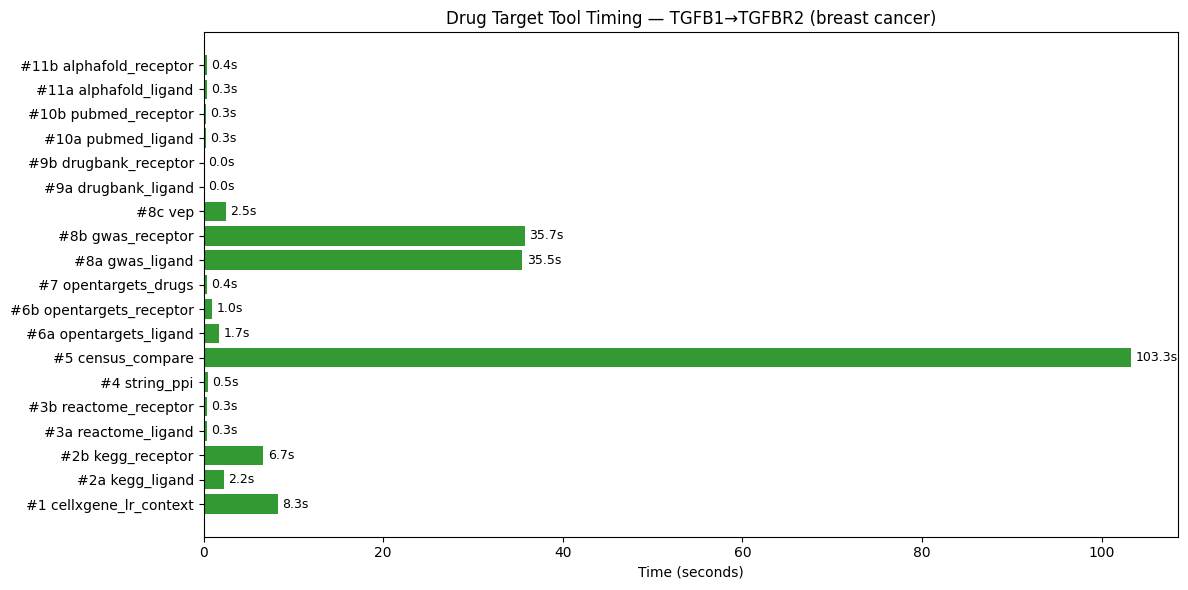

In [28]:
# Bar chart
import matplotlib.pyplot as plt

names = list(timings.keys())
times = list(timings.values())
colors = ['green' if results.get(n, {}).get('executed') else 'red' for n in names]

fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.barh(names, times, color=colors, alpha=0.8)
ax.set_xlabel('Time (seconds)')
ax.set_title(f'Drug Target Tool Timing — {LIGAND}→{RECEPTOR} ({DISEASE})')
for bar, t in zip(bars, times):
    ax.text(bar.get_width() + 0.5, bar.get_y() + bar.get_height()/2,
            f'{t:.1f}s', va='center', fontsize=9)
plt.tight_layout()
plt.show()

In [29]:
# Save all results to JSON
output_path = os.path.join(DATA_DIR, "test_all_stages.json")
with open(output_path, "w") as f:
    json.dump({
        "parameters": {
            "disease": DISEASE,
            "ligand": LIGAND,
            "receptor": RECEPTOR,
            "target_cell_type": TARGET_CELL_TYPE,
            "organism": ORGANISM,
            "uniprot_ligand": UNIPROT_LIGAND,
            "uniprot_receptor": UNIPROT_RECEPTOR,
        },
        "timings": timings,
        "results": results,
    }, f, indent=2, default=str)

print(f"Saved: {output_path}")

Saved: check_drugtarget/test_all_stages.json
